# Task 2: Advanced EDA & Text Mining on Automotive Warranty Data

### Context & Objectives
In this task, we analyze 1,000 warranty claim records (`Hanuai task2 assignment.csv`) for vehicle infotainment, audio, and navigation systems.

The dataset includes both structured operational fields (`BUILD_PLANT_DESC`, `BUILD_DATE`, `IN_USE_DATE`, `Opened date`, `MODEL`, `CAUSAL_CD_DESC`) and unstructured text fields (`CUSTOMER_VERBATIM`, `CAUSAL_VERBATIM`, `CORRECTION_VERBATIM`).

### Key Goals:
1. **EDA & Data Cleaning**: Inspect data types, nulls, duplicates, compute Time-to-Failure (Days in Service), and visualize key distributions.
2. **Text Mining & Entity Extraction**: In the original file, only the first 5 records contained sample tags (`Trigger`, `Failure Component`, `Failure Condition`, `Additional Context`, `Fix Component`, `Fix Condition`). We use these 5 seed rows as our reference ontology to extract and populate structured entity tags for all 1,000 records.
3. **Issue Categorization**: Group the mined entities and diagnostic verbatims into actionable high-level issue categories (Hardware Failure, Software Glitch, Wiring/Connection, External Connectivity, Battery/Power).
4. **Clustering & Root Cause Analysis**: Apply TF-IDF and K-Means clustering to uncover the primary failure groups and understand root causes.
5. **Export**: Save the updated, fully tagged dataset to CSV and Excel.


### 1. Setup & Imports

In [1]:
import os
import re
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 140
%matplotlib inline


### 2. Loading Data & Initial Inspection

In [2]:
df = pd.read_csv("Hanuai task2 assignment.csv")
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nMissing values per column:")
display(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Unique Event IDs: {df['Event id'].nunique()}")


Dataset shape: 1000 rows, 20 columns

Missing values per column:


Event id                 0
Opened date              0
CAUSAL_VERBATIM          1
CORRECTION_VERBATIM      0
CUSTOMER_VERBATIM        0
BUILD_DATE               0
BUILD_PLANT_DESC         0
CAUSAL_CD_DESC           3
COMPLAINT_CD_DESC        0
IN_USE_DATE              1
MAKE                     0
MODEL                    0
MODLYR                   0
PLANT                    0
Trigger                995
Failure Component      995
Failure Condition      995
Additional Context     995
Fix Component          995
Fix Condition          995
dtype: int64


Duplicate rows: 0
Unique Event IDs: 1000


### 3. Cleaning Dates & Computing Days in Service
We convert `Opened date`, `BUILD_DATE`, and `IN_USE_DATE` to datetimes (stripping timezone information to keep them consistent), then calculate the vehicle's **Days in Service** before failure (`Opened date` minus `IN_USE_DATE`).


In [3]:
# Standardize datetime formats
for col in ['Opened date', 'BUILD_DATE', 'IN_USE_DATE']:
    df[col + '_DT'] = pd.to_datetime(df[col], errors='coerce').dt.tz_localize(None)

# Fill minor text nulls
df['CAUSAL_VERBATIM'] = df['CAUSAL_VERBATIM'].fillna("No causal verbatim provided")
df['CAUSAL_CD_DESC'] = df['CAUSAL_CD_DESC'].fillna("Module/Component-Not Specified")

# Calculate Days in Service (time from delivery to warranty repair)
df['Days_In_Service'] = (df['Opened date_DT'] - df['IN_USE_DATE_DT']).dt.days

# Impute any missing or negative days with median
med_days = df['Days_In_Service'][df['Days_In_Service'] >= 0].median()
df['Days_In_Service_Clean'] = df['Days_In_Service'].apply(lambda x: med_days if pd.isna(x) or x < 0 else x)

print("Summary statistics for Days in Service:")
display(df['Days_In_Service_Clean'].describe())


Summary statistics for Days in Service:


count    1000.000000
mean      240.288000
std       154.624836
min         0.000000
25%       113.750000
50%       227.000000
75%       350.000000
max       615.000000
Name: Days_In_Service_Clean, dtype: float64

### 4. Exploratory Visualizations

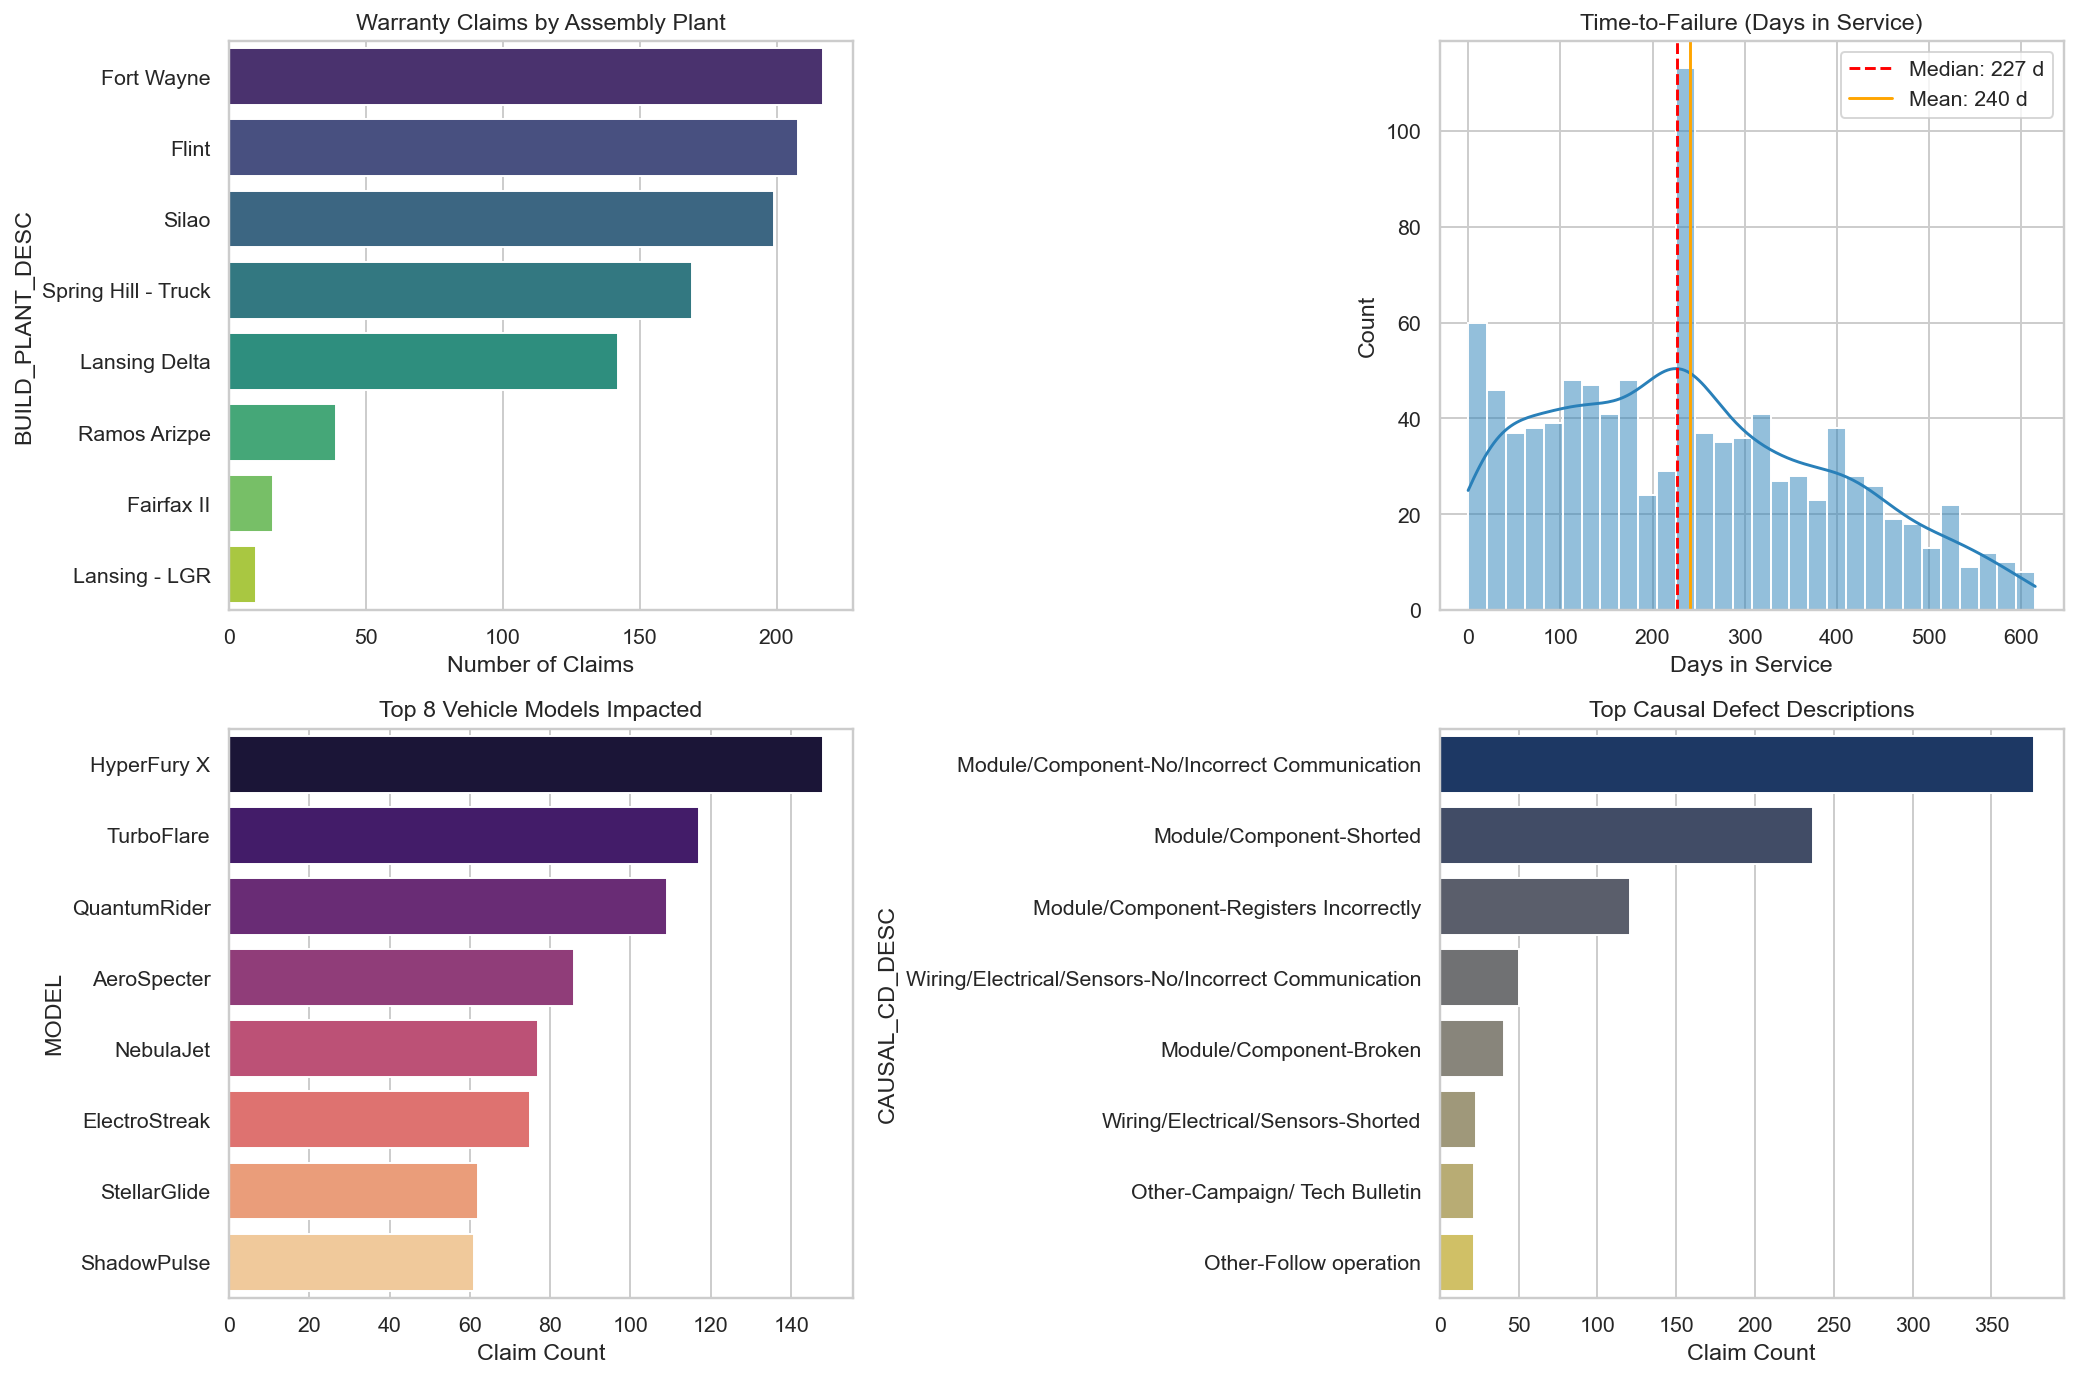

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Claims by assembly plant
plants = df['BUILD_PLANT_DESC'].value_counts()
sns.barplot(x=plants.values, y=plants.index, ax=axes[0, 0], palette="viridis", hue=plants.index, legend=False)
axes[0, 0].set_title("Warranty Claims by Assembly Plant")
axes[0, 0].set_xlabel("Number of Claims")

# 2. Time-to-failure distribution
sns.histplot(df['Days_In_Service_Clean'], bins=30, kde=True, color="#2980b9", ax=axes[0, 1])
axes[0, 1].axvline(df['Days_In_Service_Clean'].median(), color='red', linestyle='--', label=f'Median: {df["Days_In_Service_Clean"].median():.0f} d')
axes[0, 1].axvline(df['Days_In_Service_Clean'].mean(), color='orange', linestyle='-', label=f'Mean: {df["Days_In_Service_Clean"].mean():.0f} d')
axes[0, 1].set_title("Time-to-Failure (Days in Service)")
axes[0, 1].set_xlabel("Days in Service")
axes[0, 1].legend()

# 3. Top vehicle models
models = df['MODEL'].value_counts().head(8)
sns.barplot(x=models.values, y=models.index, ax=axes[1, 0], palette="magma", hue=models.index, legend=False)
axes[1, 0].set_title("Top 8 Vehicle Models Impacted")
axes[1, 0].set_xlabel("Claim Count")

# 4. Top causal codes
causal = df['CAUSAL_CD_DESC'].value_counts().head(8)
sns.barplot(x=causal.values, y=causal.index, ax=axes[1, 1], palette="cividis", hue=causal.index, legend=False)
axes[1, 1].set_title("Top Causal Defect Descriptions")
axes[1, 1].set_xlabel("Claim Count")

plt.tight_layout()
plt.show()


### 5. Text Mining & Entity Tagging
In the raw data, only the first 5 records had pre-filled values for:
- `Trigger`
- `Failure Component`
- `Failure Condition`
- `Additional Context`
- `Fix Component`
- `Fix Condition`

Rows 5 to 999 are completely null. Below, we inspect the seed examples and build an entity extraction function that parses `CUSTOMER_VERBATIM`, `CAUSAL_VERBATIM`, and `CORRECTION_VERBATIM` to populate all 1,000 rows consistently.


In [5]:
print("Seed rows provided in original file:")
display(df[['Event id', 'Failure Component', 'Failure Condition', 'Fix Component', 'Fix Condition']].head(5))

# Keyword mappings derived from domain notes & few-shot seed patterns
COMPONENTS = {
    'Radio': ['radio', 'headunit', 'silver box', 'head unit', 'receiver'],
    'Display': ['display', 'screen', 'touch screen', 'cue screen', 'monitor', 'touchscreen', 'infotainment screen', 'ipc'],
    'Audio Unit': ['audio', 'sound', 'speaker', 'volume', 'chime', 'amplifier', 'amp'],
    'Camera': ['camera', 'rearview', 'rear view', 'back up camera', 'backup camera', 'surround vision', 'front camera'],
    'Navigation / SD Card': ['navigation', 'nav', 'gps', 'sd card', 'map', 'sim card', 'card reader'],
    'Bluetooth': ['bluetooth', 'blue tooth', 'bt', 'pair', 'carplay', 'apple car play', 'android auto', 'siri'],
    'Satellite Radio / SXM': ['xm', 'sirius', 'satellite', 'sat radio', 'sattilite', 'sxm'],
    'OnStar / Telematics': ['onstar', 'on-star', 'telematics', 'tcicm', 'tcim', 'vcim', 'wifi', 'wi-fi', 'hotspot'],
    'Antenna / Coax Cable': ['antenna', 'coax', 'coaxial', 'fakra'],
    'USB / Aux Hub': ['usb', 'aux', 'receptacle', 'auxiliary'],
    'Wiring / Connectors': ['wire', 'wiring', 'harness', 'terminal', 'pin', 'connector', 'splice']
}

CONDITIONS = {
    'Black Screen': ['black screen', 'dark screen', 'screen blank', 'screen is blank', 'went blank', 'screen stays blank', 'screen is just dark', 'pitch black'],
    'No Sound / Audio Loss': ['no sound', 'no audio', 'sound cut', 'audio cut', 'loss of audio', 'silent', 'muted', 'no volume'],
    'Controls Irresponsive / Freezing': ['freeze', 'freezing', 'frozen', 'unresponsive', 'locked up', 'lock up', 'delaminating', 'not responding', 'delay', 'slow'],
    'Lost Communication': ['lost communication', 'loss of communication', 'loss of comm', 'no communication', 'no comm', 'dtc u', 'u0184', 'u0198', 'ethernet bus'],
    'Signal Lost / Loading Loop': ['signal lost', 'searching for signal', 'loading', 'acquiring signal', 'channel unavailable', 'reconnect'],
    'Update / Program Failed': ['update failed', 'failed update', 'program failed', 'return to dealer', 'unrecognized calibration', 'download failed'],
    'Language / Splash Screen Anomaly': ['arabic', 'cadillac splash', 'cadillac logo', 'spanish', 'different language', 'demo mode', 'valet mode'],
    'Parasitic Battery Drain': ['battery died', 'battery drain', 'parasitic draw', 'jump started', "won't shut off", 'stays on', 'stay awake', 'not turning off'],
    'Camera Red X / Distortion': ['red triangle', 'red x', 'pink screen', 'lines on screen', 'wavy', 'glitching', 'camera inop', 'slash through it'],
    'Internal Fault / Short': ['internal fault', 'internal failure', 'internal short', 'shorted', 'open circuit', 'hardware failure']
}

TRIGGERS = {
    'When Reversing': ['reverse', 'backing up', 'backing out', 'gear'],
    'At Startup': ['at start up', 'at startup', 'first start', 'initial start', 'key on', 'morning', 'cold start'],
    'After Remote Start': ['remote start', 'auto start'],
    'While Driving': ['while driving', 'driving down', 'road test', 'traveling'],
    'Over Bumps': ['bumps', 'going over bumps'],
    'When Cold': ['cold', 'winter'],
    'After Software Update': ['after update', 'since update', 'doing update', 'recent software update']
}

FIX_COMPONENTS = {
    'Radio': ['radio', 'receiver', 'silver box', 'headunit', 'radio module'],
    'SPS': ['sps', 'programming', 'reprogrammed', 'reflashed', 'calibrations', 'tis'],
    'USB': ['usb', 'file transfer', 'flash drive', 'usb update'],
    'Display': ['display', 'screen', 'center stack', 'bezel'],
    'SD Card': ['sd card', 'nav card', 'memory card'],
    'Aux / USB Receptacle': ['receptacle', 'auxiliary input', 'usb port', 'hub'],
    'Coax Cable': ['coax cable', 'coaxial', 'fakra'],
    'Antenna': ['antenna'],
    'Amplifier': ['amplifier', 'amp'],
    'Wiring / Connector': ['connector', 'terminal', 'lead', 'dielectric grease', 'harness', 'splice']
}

FIX_CONDITIONS = {
    'Replaced': ['replaced', 'replace', 'r&r', 'r-r', 'installed new', 'exchange unit', 'remv/repl'],
    'Programmed': ['programmed', 'reprogrammed', 'sps', 'usb file transfer', 'setup', 'calibrated', 'configured'],
    'Repaired / Adjusted': ['repaired', 'adjusted', 'depinned', 'cleaned', 'relocated', 'reseat', 'tightened'],
    'Reset': ['global reset', 'factory reset', 'mec reset', 'power cycle']
}

def extract_tags(cust, causal, corr):
    blob = f"{cust} {causal} {corr}".lower()
    
    trigs = [k for k, v in TRIGGERS.items() if any(w in blob for w in v)] or ['No Additional Functionality']
    fcomps = [k for k, v in COMPONENTS.items() if any(w in blob for w in v)] or ['Radio']
    fconds = [k for k, v in CONDITIONS.items() if any(w in blob for w in v)] or ['Internal Fault']
    
    ctx = []
    if 'while driving' in blob: ctx.append('While Driving')
    if any(k in blob for k in ['battery', 'boost', 'dead']): ctx.append('Low Battery / Boost Event')
    if any(k in blob for k in ['phone', 'bluetooth']): ctx.append('Phone Integration Context')
    if 'update' in blob: ctx.append('Software Update Context')
    if not ctx: ctx = ['No Additional Context']
    
    corr_lower = str(corr).lower()
    fix_c = [k for k, v in FIX_COMPONENTS.items() if any(w in corr_lower for w in v)] or ['Radio']
    fix_cond = [k for k, v in FIX_CONDITIONS.items() if any(w in corr_lower for w in v)] or ['Replaced']
    
    return str(trigs), str(fcomps), str(fconds), str(ctx), str(fix_c), str(fix_cond)

# Apply entity tagging across all records (preserving seed rows)
for idx in range(len(df)):
    if idx >= 5 or pd.isna(df.loc[idx, 'Failure Component']):
        t, fc, fcond, c, fxc, fxcond = extract_tags(
            df.loc[idx, 'CUSTOMER_VERBATIM'],
            df.loc[idx, 'CAUSAL_VERBATIM'],
            df.loc[idx, 'CORRECTION_VERBATIM']
        )
        df.loc[idx, 'Trigger'] = t
        df.loc[idx, 'Failure Component'] = fc
        df.loc[idx, 'Failure Condition'] = fcond
        df.loc[idx, 'Additional Context'] = c
        df.loc[idx, 'Fix Component'] = fxc
        df.loc[idx, 'Fix Condition'] = fxcond

print("Entity extraction completed for all 1,000 records.")
display(df[['Event id', 'Trigger', 'Failure Component', 'Failure Condition', 'Fix Component', 'Fix Condition']].head(5))


Seed rows provided in original file:


,Event id,Failure Component,Failure Condition,Fix Component,Fix Condition
0,D-14801,"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']","['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']","['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['Radio'],['Replaced']
3,D-14704,['Display'],['Black Screen'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,['Radio'],['Malfunction'],['Radio'],['Replaced']


Entity extraction completed for all 1,000 records.


,Event id,Trigger,Failure Component,Failure Condition,Fix Component,Fix Condition
0,D-14801,['No Additional Functionality'],"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']","['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,['No Additional Functionality'],"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']","['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,['No Additional Functionality'],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['Radio'],['Replaced']
3,D-14704,['When Reversing'],['Display'],['Black Screen'],"['Radio', 'USB']","['Replaced', 'Programmed']"
4,D-15142,['No Additional Functionality'],['Radio'],['Malfunction'],['Radio'],['Replaced']


### 6. High-Level Issue Classification
Based on the extracted entities and diagnostic narratives, we classify each claim into one of five functional issue categories:
1. Internal Component Hardware Failure
2. Software, Firmware & Calibration Glitch
3. Wiring & Physical Connection Quality
4. Connectivity & External Signal Reception
5. Power Management & Parasitic Draw


Issue Category Counts:


Issue_Category
Internal Component Hardware Failure         437
Software, Firmware & Calibration Glitch     295
Wiring & Physical Connection Quality        144
Connectivity & External Signal Reception    108
Power Management & Parasitic Draw            16
Name: count, dtype: int64

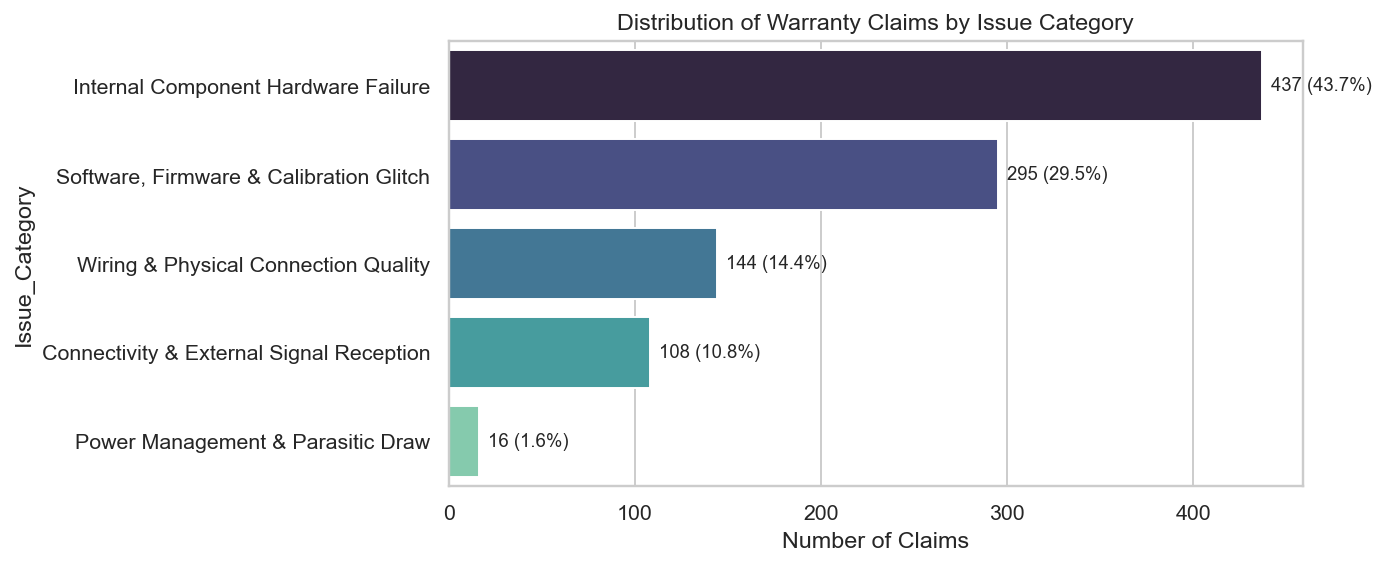

In [6]:
def categorize(row):
    text = (str(row['CUSTOMER_VERBATIM']) + " " + str(row['CAUSAL_VERBATIM']) + " " + str(row['CORRECTION_VERBATIM'])).lower()
    
    if any(k in text for k in ['coax', 'cable', 'terminal', 'loose connection', 'bent pin', 'poor contact', 'fretting', 'harness']):
        return "Wiring & Physical Connection Quality"
    elif any(k in text for k in ['update failed', 'sps', 'usb update', 'logic lock', 'arabic', 'cadillac splash', 'demo mode', 'software anomaly', 'reprogram']):
        return "Software, Firmware & Calibration Glitch"
    elif any(k in text for k in ['satellite lost', 'searching for signal', 'xm', 'sirius', 'bluetooth disconnect', 'pair phone', 'wifi', 'onstar']):
        return "Connectivity & External Signal Reception"
    elif any(k in text for k in ['battery drain', 'parasitic', 'stays on', "won't shut off", "won't turn off", 'power mode']):
        return "Power Management & Parasitic Draw"
    else:
        return "Internal Component Hardware Failure"

df['Issue_Category'] = df.apply(categorize, axis=1)

print("Issue Category Counts:")
display(df['Issue_Category'].value_counts())

plt.figure(figsize=(10, 4.2))
counts = df['Issue_Category'].value_counts()
sns.barplot(x=counts.values, y=counts.index, palette="mako", hue=counts.index, legend=False)
plt.title("Distribution of Warranty Claims by Issue Category")
plt.xlabel("Number of Claims")
for i, v in enumerate(counts.values):
    plt.text(v + 5, i, f"{v} ({v/len(df)*100:.1f}%)", va='center', fontsize=9.5)
plt.tight_layout()
plt.show()


### 7. Unsupervised Clustering & Root Cause Identification
We vectorize the combined verbatims using TF-IDF (unigrams + bigrams) and cluster the claims using K-Means ($k=5$). This helps discover natural failure modes without relying strictly on human-assigned categories.


In [7]:
def clean_text_corpus(t):
    t = re.sub(r'[^a-zA-Z\s]', ' ', str(t).lower())
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['Full_Verbatim'] = df['CUSTOMER_VERBATIM'] + " " + df['CAUSAL_VERBATIM'] + " " + df['CORRECTION_VERBATIM']
df['Clean_Verbatim'] = df['Full_Verbatim'].apply(clean_text_corpus)

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=2500,
    ngram_range=(1, 2),
    min_df=3
)
X_tfidf = tfidf.fit_transform(df['Clean_Verbatim'])

# Run K-Means with 5 clusters
km = KMeans(n_clusters=5, random_state=42, n_init=15)
df['Cluster'] = km.fit_predict(X_tfidf)

# Inspect top terms in each cluster
terms = tfidf.get_feature_names_out()
order_centroids = km.cluster_centers_.argsort()[:, ::-1]

cluster_map = {
    0: "Cluster 0: Black Screen Display & Inoperative Radio Module",
    1: "Cluster 1: Rearview / Surround Camera Video Loss & Coax Fault",
    2: "Cluster 2: Firmware Updates, SPS/USB Programming & TAC Escalations",
    3: "Cluster 3: SiriusXM Satellite Reception Loss & Audio Mute",
    4: "Cluster 4: Navigation SD Card Hub & Map Inaccuracy Errors"
}

df['Cluster_Label'] = df['Cluster'].map(cluster_map)

print("K-Means Top Terms per Cluster:")
for i in range(5):
    top_w = [terms[ind] for ind in order_centroids[i, :7]]
    print(f"\n{cluster_map[i]} (Count: {sum(df['Cluster'] == i)}):")
    print(f"  Key words: {', '.join(top_w)}")


K-Means Top Terms per Cluster:

Cluster 0: Black Screen Display & Inoperative Radio Module (Count: 328):
  Key words: radio, screen, blank, radio screen, communication, internal, module

Cluster 1: Rearview / Surround Camera Video Loss & Coax Fault (Count: 94):
  Key words: camera, radio, rear, coax, camera inop, video, backup

Cluster 2: Firmware Updates, SPS/USB Programming & TAC Escalations (Count: 371):
  Key words: radio, tac, customer, update, usb, vehicle, replaced

Cluster 3: SiriusXM Satellite Reception Loss & Audio Mute (Count: 160):
  Key words: radio, xm, xm radio, replace, replace radio, signal, internal

Cluster 4: Navigation SD Card Hub & Map Inaccuracy Errors (Count: 47):
  Key words: card, sd, sd card, error, navigation, radio, error code


### 8. Visualizing Clusters with PCA (2D Projection)

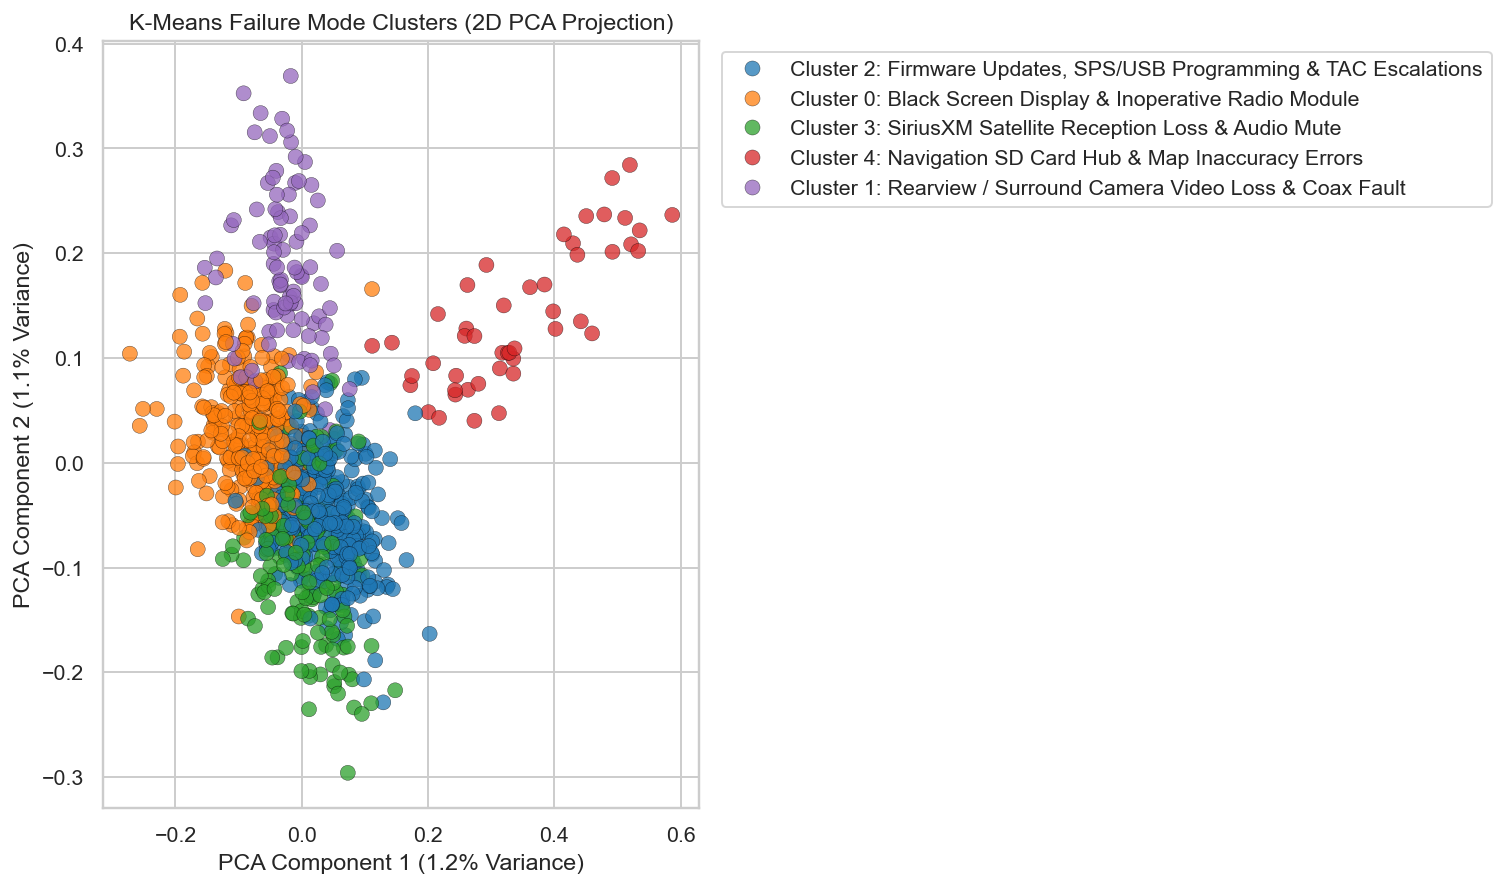

In [8]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_tfidf.toarray())
df['PCA1'] = coords[:, 0]
df['PCA2'] = coords[:, 1]

plt.figure(figsize=(11, 6.5))
sns.scatterplot(
    data=df, x='PCA1', y='PCA2', hue='Cluster_Label',
    palette="tab10", alpha=0.75, s=60, edgecolor='black', linewidth=0.2
)
plt.title("K-Means Failure Mode Clusters (2D PCA Projection)")
plt.xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 9. Saving the Enriched Dataset

In [9]:
export_cols = [
    'Event id', 'Opened date', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM', 'CUSTOMER_VERBATIM',
    'BUILD_DATE', 'BUILD_PLANT_DESC', 'CAUSAL_CD_DESC', 'COMPLAINT_CD_DESC', 'IN_USE_DATE',
    'MAKE', 'MODEL', 'MODLYR', 'PLANT',
    'Days_In_Service_Clean',
    'Trigger', 'Failure Component', 'Failure Condition', 'Additional Context', 'Fix Component', 'Fix Condition',
    'Issue_Category', 'Cluster', 'Cluster_Label'
]

final_export_t2 = df[export_cols].copy()
final_export_t2.rename(columns={'Days_In_Service_Clean': 'Days_In_Service'}, inplace=True)

final_export_t2.to_csv("task2_enriched_automotive_warranty.csv", index=False)
final_export_t2.to_excel("task2_enriched_automotive_warranty.xlsx", index=False)

print(f"Enriched dataset successfully exported ({len(final_export_t2)} records) to:")
print(" - task2_enriched_automotive_warranty.csv")
print(" - task2_enriched_automotive_warranty.xlsx")


Enriched dataset successfully exported (1000 records) to:
 - task2_enriched_automotive_warranty.csv
 - task2_enriched_automotive_warranty.xlsx
